# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [40]:
%pylab inline
import pandas as pd

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

Populating the interactive namespace from numpy and matplotlib


## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [41]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [42]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
import numpy as np

Ridge, |coef|<tol: 0
Lasso, |coef|<tol: 7
          Ridge       Lasso
age   20.865881    0.000000
sex  -58.000391    0.000000
bmi  231.270469  274.331284
bp   186.670104   48.572037
s1    33.310872    0.000000
s2    -2.169947    0.000000
s3  -150.950494   -0.000000
s4   141.350365    0.000000
s5   250.753913  424.121427
s6   123.180258    0.000000


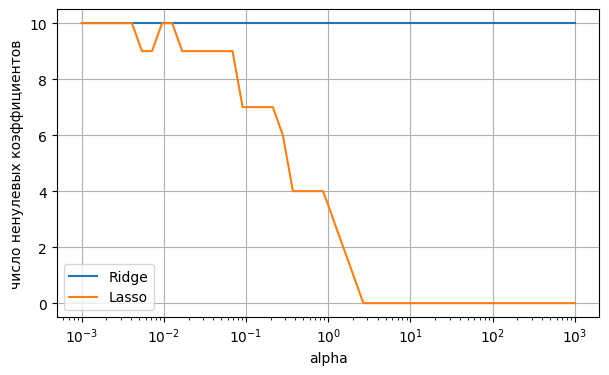

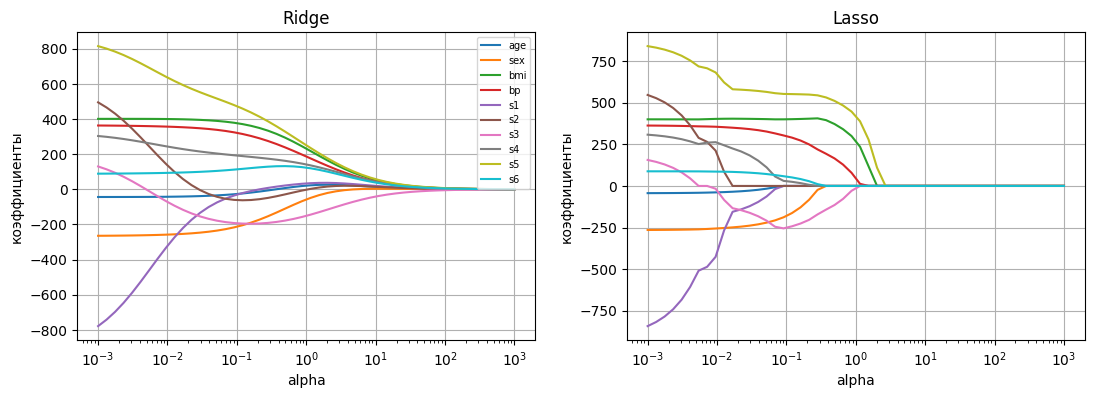

In [43]:
ridge = Ridge().fit(X_train, y_train)
lasso = Lasso().fit(X_train, y_train)

tol = 1e-3
print("Ridge, |coef|<tol:", np.sum(np.abs(ridge.coef_) < tol))
print("Lasso, |coef|<tol:", np.sum(np.abs(lasso.coef_) < tol))
print(pd.DataFrame({"Ridge": ridge.coef_, "Lasso": lasso.coef_}, index=data.feature_names))

alphas = np.logspace(-3, 3, 50)
coefs_r, coefs_l = [], []
for a in alphas:
    coefs_r.append(Ridge(alpha=a).fit(X_train, y_train).coef_)
    coefs_l.append(Lasso(alpha=a, max_iter=100000).fit(X_train, y_train).coef_)
coefs_r, coefs_l = np.array(coefs_r), np.array(coefs_l)

nz_r = (np.abs(coefs_r) > tol).sum(axis=1)
nz_l = (np.abs(coefs_l) > tol).sum(axis=1)

plt.figure(figsize=(7, 4))
plt.semilogx(alphas, nz_r, label="Ridge")
plt.semilogx(alphas, nz_l, label="Lasso")
plt.xlabel("alpha"); plt.ylabel("число ненулевых коэффициентов")
plt.legend(); plt.grid(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for axi, c, name in zip(ax, [coefs_r, coefs_l], ["Ridge", "Lasso"]):
    axi.semilogx(alphas, c)
    axi.set_title(name); axi.set_xlabel("alpha"); axi.set_ylabel("коэффициенты")
    axi.grid()
ax[0].legend(data.feature_names, fontsize=7)
plt.show()

Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [44]:
from sklearn.model_selection import cross_val_score, cross_val_predict

In [45]:
def report(model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    p = model.predict(Xte)
    return {"RMSE": np.sqrt(mean_squared_error(yte, p)),
            "MAE": mean_absolute_error(yte, p),
            "R2": r2_score(yte, p)}

print("test:", report(Ridge(), X_train, y_train, X_test, y_test))

for name, scoring in [("RMSE", "neg_root_mean_squared_error"),
                      ("MAE", "neg_mean_absolute_error"),
                      ("R2", "r2")]:
    s = cross_val_score(Ridge(), X_train, y_train, cv=5, scoring=scoring)
    print(name, abs(s.mean()))

test: {'RMSE': np.float64(58.30429511391227), 'MAE': 49.602750809651916, 'R2': 0.3599020220009461}
RMSE 59.923119379963246
MAE 50.08562512347436
R2 0.4135804855284532


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

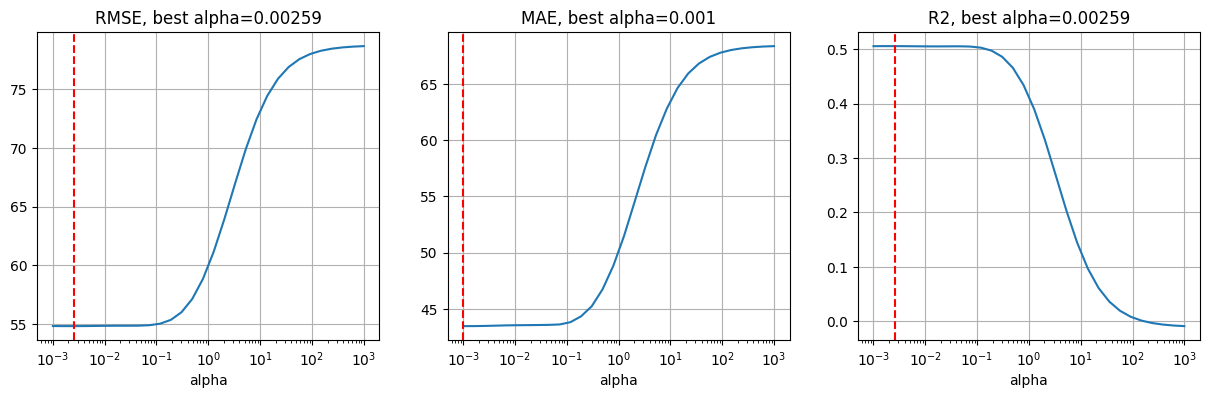

RMSE 0.002592943797404667 {'RMSE': np.float64(55.80635555978857), 'MAE': 47.10906308144855, 'R2': 0.41357472455927646}
MAE 0.001 {'RMSE': np.float64(55.857555162611526), 'MAE': 47.15542977613068, 'R2': 0.41249819791629294}
R2 0.002592943797404667 {'RMSE': np.float64(55.80635555978857), 'MAE': 47.10906308144855, 'R2': 0.41357472455927646}


In [46]:
alphas = np.logspace(-3, 3, 30)
scorers = {"RMSE": "neg_root_mean_squared_error",
           "MAE": "neg_mean_absolute_error",
           "R2": "r2"}
best = {}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for axi, (name, sc) in zip(ax, scorers.items()):
    gs = GridSearchCV(Ridge(), {"alpha": alphas}, scoring=sc, cv=5).fit(X_train, y_train)
    vals = gs.cv_results_["mean_test_score"]
    if name != "R2":
        vals = -vals
    axi.semilogx(alphas, vals)
    axi.axvline(gs.best_params_["alpha"], color="r", ls="--")
    axi.set_title(f"{name}, best alpha={gs.best_params_['alpha']:.3g}")
    axi.set_xlabel("alpha"); axi.grid()
    best[name] = gs.best_params_["alpha"]
plt.show()

for name, a in best.items():
    print(name, a, report(Ridge(alpha=a), X_train, y_train, X_test, y_test))

__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

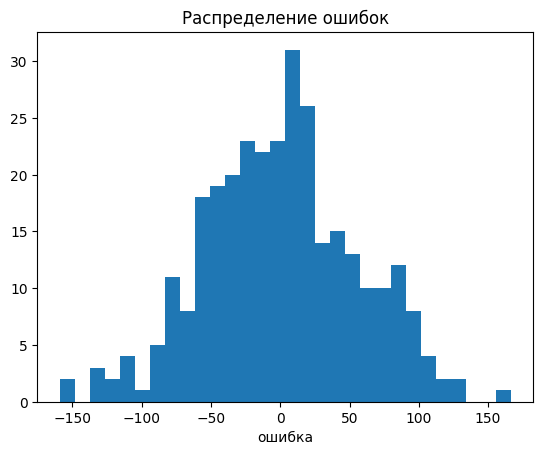

std: 54.92500975810607  max |err|: 166.38641565036747


In [47]:
model = Ridge(alpha=best["RMSE"])
pred_cv = cross_val_predict(model, X_train, y_train, cv=5)
err = y_train - pred_cv

plt.hist(err, bins=30)
plt.xlabel("ошибка"); plt.title("Распределение ошибок"); plt.show()
print("std:", err.std(), " max |err|:", np.abs(err).max())

Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [48]:
mask = np.abs(err) < 2.5 * err.std()
print("удалено объектов:", (~mask).sum(), "из", len(mask))

before = report(Ridge(alpha=best["RMSE"]), X_train, y_train, X_test, y_test)
after = report(Ridge(alpha=best["RMSE"]), X_train[mask], y_train[mask], X_test, y_test)
print(pd.DataFrame([before, after], index=["с выбросами", "без выбросов"]))

удалено объектов: 3 из 309
                   RMSE        MAE        R2
с выбросами   55.806356  47.109063  0.413575
без выбросов  55.931738  47.007222  0.410937


__Задание 3.__ Отчёт

**(2 балла)**

**Данные.** Датасет `load_diabetes` (10 признаков), разбиение на train/test 70/30. Метрики: RMSE, MAE, R².

### 1. Ridge и Lasso
При параметрах по умолчанию (alpha=1) Ridge не обнулил ни одного коэффициента, а Lasso обнулил 7 из 10. Ненулевыми остались `bmi`, `bp` и `s5`, то есть L1-регуляризация отбирает признаки, а L2 только уменьшает веса. На графиках по сетке alpha от 10⁻³ до 10³ видно, что при росте alpha все коэффициенты стремятся к нулю. У Lasso они обнуляются резко, у Ridge затухают плавно.

### 2. Метрики и подбор alpha
Ridge (alpha=1) на тесте: RMSE ≈ 58.30, MAE ≈ 49.60, R² ≈ 0.36. Результаты кросс-валидации близки, значит, переобучения нет.

Подбор alpha через GridSearchCV (5 фолдов, сетка 10⁻³…10³):

| Метрика | Лучший alpha | RMSE | MAE | R² |
|---|---|---|---|---|
| RMSE | ≈ 0.0026 | 55.81 | 47.11 | 0.414 |
| MAE | 0.001 | 55.86 | 47.16 | 0.412 |
| R² | ≈ 0.0026 | 55.81 | 47.11 | 0.414 |

Качество заметно улучшилось: RMSE упал с 58.3 до 55.8, R² вырос с 0.36 до 0.41. Оптимальный alpha очень мал, то есть модель близка к обычной линейной регрессии, а alpha=1 по умолчанию оказался слишком сильной регуляризацией. Выбор метрики на результат почти не влияет.

### 3. Выбросы
Стандартное отклонение ошибок (out-of-fold) ≈ 54.9, максимальная ошибка ≈ 166 (около 3σ), то есть тяжёлых хвостов нет. Выбросами считались объекты с |ошибка| > 2.5σ, таких оказалось 3 из 309.

| Модель | RMSE | MAE | R² |
|---|---|---|---|
| С выбросами | 55.81 | 47.11 | 0.4136 |
| Без выбросов | 55.93 | 47.01 | 0.4109 |

Качество не улучшилось. Причины: выбросов очень мало (~1%), сильных выбросов в данных нет, в тесте выбросы тоже есть и от обучения не зависят, а удаление объектов слегка уменьшает выборку.

### Итог
Главный выигрыш дал подбор коэффициента регуляризации: RMSE снизился примерно на 4%, R² вырос с 0.36 до 0.41. Lasso показал, что наиболее информативны признаки `bmi`, `bp` и `s5`. Удаление выбросов эффекта не дало, поэтому итоговая модель — Ridge с подобранным alpha на всех данных.
